# Day 23: Per-90 Metrics and Normalization in Football

**Phase 2: EDA & Feature Engineering**

## Objective
Implement per-90 normalization for all player metrics. Discuss appropriateness vs totals vs possession. Implement percentile rankings by position. Create comparative radar charts (pizza plots).

**Deliverable:** Notebook `day023_per_90_and_radar_charts.ipynb` with 4+ publishable radar charts.


### 1. Architectural Setup & Theoretical Foundation

#### Mathematical Formulation: The Denominator Problem
When comparing players, raw counting statistics (totals) are biased towards players with more accumulated game time. Normalizing to a standard 90-minute baseline solves this:

$$\text{Metric}_{p90} = \frac{\sum \text{Metric}}{\text{Minutes Played}} \times 90$$

However, if $\text{Minutes Played}$ is approximated by static 90-minute periods, we introduce significant noise. The 2022 FIFA World Cup averaged over 10 minutes of stoppage time per game. An accurate calculation must:
1. Identify starting XI players ($t_{\text{in}} = 0$).
2. Track substitution timestamps ($t_{\text{out}}$ for departing players, $t_{\text{in}}$ for incoming substitutes).
3. Track red cards / expulsions ($t_{\text{out}}$).
4. Account for exact period stoppage times and extra time (Periods 1, 2, 3, 4).


In [28]:
# 1. Standard Library & Third-Party Imports
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Pitch visualization & radar plots
from mplsoccer import PyPizza, FontManager

# Visualization configuration
plt.style.use('default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']

# Locate project root
project_root = Path.cwd().resolve()
while not (project_root / 'src').exists() and project_root.parent != project_root:
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(f'Project root resolved to: {project_root}')


Project root resolved to: /Users/davidbazalduamendez/Documents/GitHub/100-days-Data-Sports-Challenge


### 2. Event Log Ingestion & Schema Inspection
We load the full StatsBomb 2022 World Cup dataset (`sb_events_43_106.parquet`). We inspect key match management event types (`Starting XI` and `Substitution`) as well as period structures.


In [29]:
# 1. Define paths
events_parquet_path = project_root / 'data' / 'raw' / 'statsbomb' / 'sb_events_43_106.parquet'
dim_players_path = project_root / 'data' / 'processed' / 'football' / 'dim_players.parquet'
dim_matches_path = project_root / 'data' / 'processed' / 'football' / 'dim_matches.parquet'

# 2. Ingest raw events
print(f'Loading event logs from: {events_parquet_path.name}...')
df_events = pd.read_parquet(events_parquet_path)
print(f'Loaded {len(df_events):,} events across {df_events["match_id"].nunique()} matches.')

# 3. Quick audit of event types related to match tracking
tracking_types = ['Starting XI', 'Substitution', 'Half End', 'Half Start', 'Bad Behaviour']
lineup_subs_events = df_events[df_events['type'].isin(tracking_types)]['type'].value_counts()
print('\n--- Match Management Event Distribution ---')
print(lineup_subs_events)


Loading event logs from: sb_events_43_106.parquet...
Loaded 234,652 events across 64 matches.

--- Match Management Event Distribution ---
type
Substitution     587
Half Start       286
Half End         286
Starting XI      128
Bad Behaviour     44
Name: count, dtype: int64


### 3. Deep Dive: Lineup Tactics & Substitutions (Case Study: World Cup Final)
We examine Match ID `3869685` (Argentina vs France - World Cup Final, which went through regulation time, extra time, and penalty shootout) to verify how player entries and departures are registered in StatsBomb data.


In [30]:
# Target match: World Cup Final 2022 (Argentina vs France)
SAMPLE_MATCH_ID = 3869685
df_sample = df_events[df_events['match_id'] == SAMPLE_MATCH_ID].copy()

# 1. Starting XI Inspection
starting_xi_events = df_sample[df_sample['type'] == 'Starting XI']
print(f'Starting XI event rows: {len(starting_xi_events)} (1 per team)')

# Inspect the first team lineup structure inside tactics
team_lineup_sample = starting_xi_events.iloc[0]['tactics']['lineup']
df_lineup_preview = pd.DataFrame(team_lineup_sample)
print(f'Lineup keys inside tactics: {list(team_lineup_sample[0].keys())}')
display(df_lineup_preview.head(5))

# 2. Substitution Inspection
subs_cols = ['minute', 'second', 'period', 'team', 'player', 'substitution_replacement']
subs_events = df_sample[df_sample['type'] == 'Substitution'][subs_cols].sort_values(['period', 'minute', 'second'])

print(f'\nTotal Substitutions in Sample Match: {len(subs_events)}')
display(subs_events.head(6))


Starting XI event rows: 2 (1 per team)
Lineup keys inside tactics: ['jersey_number', 'player', 'position']


,0
0,"{'jersey_number': 23, 'player': {'id': 6909, '..."
1,"{'jersey_number': 26, 'player': {'id': 29201, ..."
2,"{'jersey_number': 13, 'player': {'id': 20572, ..."
3,"{'jersey_number': 19, 'player': {'id': 3090, '..."
4,"{'jersey_number': 3, 'player': {'id': 5507, 'n..."



Total Substitutions in Sample Match: 13


,minute,second,period,team,player,substitution_replacement
36716,40,32,1,France,Ousmane Dembélé,Randal Kolo Muani
36717,41,1,1,France,Olivier Giroud,Marcus Thuram
36718,63,51,2,Argentina,Ángel Fabián Di María Hernández,Marcos Javier Acuña
36719,70,27,2,France,Theo Bernard François Hernández,Eduardo Camavinga
36720,70,29,2,France,Antoine Griezmann,Kingsley Coman
36721,90,0,3,Argentina,Nahuel Molina Lucero,Gonzalo Ariel Montiel


### 4. Robust Real-Minutes Calculation Engine (`get_match_player_minutes`)

#### Algorithmic Breakdown
To calculate the exact playing time for each player in a match across regular and extra-time periods ($P \in \{1, 2, 3, 4\}$):
1. **Period Duration**: Compute the true end timestamp of each period:
   $$\text{Duration}(P) = \max(t) - \text{BaseMinute}(P)$$
   where $\text{BaseMinute} = \{1: 0, 2: 45, 3: 90, 4: 105\}$.
2. **Starting XI Players**: Enter at $(P=1, t=0.0)$. If not substituted or sent off, they play all active periods.
3. **Substitutions**: Departing player exits at $(P_{\text{sub}}, t_{\text{sub}})$; incoming substitute enters at $(P_{\text{sub}}, t_{\text{sub}})$.
4. **Red Cards / Expulsions**: Exits the pitch at $(P_{\text{card}}, t_{\text{card}})$.
5. **Total Minutes**: For each player, sum the active minutes played across all periods.


In [31]:
def get_match_player_minutes(df_match: pd.DataFrame) -> pd.DataFrame:
    """
    Calculates the exact minutes played for each player in a single match,
    accounting for starting lineups, substitutions, expulsions, and added time
    across regulation and extra time periods (1, 2, 3, 4).

    Args:
        df_match: DataFrame containing all events for a single match_id.

    Returns:
        DataFrame with columns: [match_id, player_id, player_name, team_name,
                                primary_position, is_starter, minutes_played].
    """
    match_id = df_match['match_id'].iloc[0]
    base_minutes = {1: 0.0, 2: 45.0, 3: 90.0, 4: 105.0}
    
    # 1. Determine active periods and exact period bounds (excluding penalty shootouts: period 5)
    active_periods = sorted([p for p in df_match['period'].unique() if p in [1, 2, 3, 4]])
    period_bounds = {}
    for p in active_periods:
        p_events = df_match[df_match['period'] == p]
        start_t = base_minutes.get(p, 0.0)
        max_t = (p_events['minute'] + p_events['second'] / 60.0).max()
        period_bounds[p] = {'start': start_t, 'end': max_t, 'duration': max_t - start_t}

    # 2. Extract Starting XI
    players = {}
    starting_events = df_match[df_match['type'] == 'Starting XI']
    for _, row in starting_events.iterrows():
        team = row['team']
        lineup = row['tactics']['lineup']
        for item in lineup:
            p_id = item['player']['id']
            p_name = item['player']['name']
            pos = item['position']['name']
            players[p_id] = {
                'match_id': match_id,
                'player_id': p_id,
                'player_name': p_name,
                'team_name': team,
                'primary_position': pos,
                'is_starter': True,
                'period_in': 1,
                'time_in': 0.0,
                'period_out': active_periods[-1],
                'time_out': period_bounds[active_periods[-1]]['end']
            }

    # 3. Process Substitutions
    subs = df_match[df_match['type'] == 'Substitution'].sort_values(['period', 'minute', 'second'])
    for _, row in subs.iterrows():
        out_id = row['player_id']
        in_id = row['substitution_replacement_id']
        in_name = row['substitution_replacement']
        team = row['team']
        sub_period = row['period']
        sub_time = row['minute'] + row['second'] / 60.0
        
        # Update departing player
        if out_id in players:
            players[out_id]['period_out'] = sub_period
            players[out_id]['time_out'] = sub_time
            
        # Register incoming substitute
        # Infer position from subsequent on-ball events if available, or default to out_player position
        sub_pos = players[out_id]['primary_position'] if out_id in players else 'Substitute'
        players[in_id] = {
            'match_id': match_id,
            'player_id': in_id,
            'player_name': in_name,
            'team_name': team,
            'primary_position': sub_pos,
            'is_starter': False,
            'period_in': sub_period,
            'time_in': sub_time,
            'period_out': active_periods[-1],
            'time_out': period_bounds[active_periods[-1]]['end']
        }

    # 4. Process Red Cards / Expulsions
    card_filter = (
        df_match['foul_committed_card'].isin(['Red Card', 'Second Yellow']) |
        df_match['bad_behaviour_card'].isin(['Red Card', 'Second Yellow'])
    )
    red_cards = df_match[card_filter]
    for _, row in red_cards.iterrows():
        rc_id = row['player_id']
        rc_period = row['period']
        rc_time = row['minute'] + row['second'] / 60.0
        if rc_id in players:
            players[rc_id]['period_out'] = rc_period
            players[rc_id]['time_out'] = rc_time

    # 5. Compute exact minutes played per period
    results = []
    for p_id, p_data in players.items():
        total_minutes = 0.0
        for p in active_periods:
            p_start = period_bounds[p]['start']
            p_end = period_bounds[p]['end']
            
            # Check if player participated in period p
            if p < p_data['period_in'] or p > p_data['period_out']:
                continue
            
            # Period entry time
            t_entry = p_data['time_in'] if p == p_data['period_in'] else p_start
            # Period exit time
            t_exit = p_data['time_out'] if p == p_data['period_out'] else p_end
            
            duration = max(0.0, t_exit - t_entry)
            total_minutes += duration
            
        p_data['minutes_played'] = round(total_minutes, 2)
        results.append(p_data)
        
    df_res = pd.DataFrame(results)
    cols = ['match_id', 'player_id', 'player_name', 'team_name', 'primary_position', 'is_starter', 'minutes_played']
    return df_res[cols].sort_values(['team_name', 'is_starter', 'minutes_played'], ascending=[True, False, False]).reset_index(drop=True)


### Validation: World Cup Final Player Minutes

Verify get_match_player_minutes on the 2022 World Cup Final (Argentina vs. France) including extra time and substitutions.

In [32]:
# Test get_match_player_minutes on the 2022 World Cup Final (Argentina vs France)
df_final_minutes = get_match_player_minutes(df_sample)

print(f"Total Players Active in Final: {len(df_final_minutes)} (Starters + Substitutes)")
print("\n--- Key Players Minutes Audit (Final: 120+ mins + Stoppage Time) ---")
key_players = ['Lionel Andrés Messi Cuccittini', 'Kylian Mbappé Lottin', 'Ángel Fabián Di María Hernández', 'Eduardo Camavinga']
display(df_final_minutes[df_final_minutes['player_name'].isin(key_players)])

print("\n--- Top 10 Playing Time in Final ---")
display(df_final_minutes.head(10))


Total Players Active in Final: 35 (Starters + Substitutes)

--- Key Players Minutes Audit (Final: 120+ mins + Stoppage Time) ---


,match_id,player_id,player_name,team_name,primary_position,is_starter,minutes_played
4,3869685,5503.0,Lionel Andrés Messi Cuccittini,Argentina,Right Wing,True,141.37
10,3869685,2995.0,Ángel Fabián Di María Hernández,Argentina,Left Wing,True,71.42
20,3869685,3009.0,Kylian Mbappé Lottin,France,Left Wing,True,141.37
30,3869685,24778.0,Eduardo Camavinga,France,Left Back,False,63.35



--- Top 10 Playing Time in Final ---


,match_id,player_id,player_name,team_name,primary_position,is_starter,minutes_played
0,3869685,6909.0,Damián Emiliano Martínez,Argentina,Goalkeeper,True,141.37
1,3869685,20572.0,Cristian Gabriel Romero,Argentina,Right Center Back,True,141.37
2,3869685,3090.0,Nicolás Hernán Otamendi,Argentina,Left Center Back,True,141.37
3,3869685,38718.0,Enzo Fernandez,Argentina,Center Defensive Midfield,True,141.37
4,3869685,5503.0,Lionel Andrés Messi Cuccittini,Argentina,Right Wing,True,141.37
5,3869685,5507.0,Nicolás Alejandro Tagliafico,Argentina,Left Back,True,138.02
6,3869685,27886.0,Alexis Mac Allister,Argentina,Left Center Midfield,True,132.62
7,3869685,29560.0,Julián Álvarez,Argentina,Center Forward,True,118.00
8,3869685,7797.0,Rodrigo Javier De Paul,Argentina,Right Center Midfield,True,117.80
9,3869685,29201.0,Nahuel Molina Lucero,Argentina,Right Back,True,106.18


#### Takeaways & Empirical Validation: Block 4
- **Stoppage Time Distortion (+21.37 min in Final)**: Both Messi and Mbappé registered **141.37 real minutes** instead of the nominal 120.0. Approximating their time as 120 minutes would overestimate their per-90 event rates by **+17.8%** ($141.37 / 120 = 1.178$).
- **The Di María Case (71.42 min vs 64 nominal)**: Di María was substituted in minute 63:51 of the second half, but he also completed 7.51 minutes of first-half stoppage time, totaling **71.42 minutes**.
- **Substitute Impact (Camavinga 63.35 min)**: Entered in minute 70:27 as a non-starter and played through both extra time periods, accumulating more minutes than several starters.
- **Conclusion**: Calculating the exact denominator across every active match period is indispensable for unbiased per-90 feature engineering.


### 5. Tournament-Wide Minutes Aggregation & Configurable Threshold Architecture

#### Engineering a Scalable Sample Filter
In production scouting pipelines, the sample threshold should never be hardcoded. It depends on competition structure:
- **Domestic League Season (38 matchdays)**: Typically $\ge 900$ to $1,200$ minutes ($\approx 25\text{-}30\%$ of total minutes).
- **International Tournament / Cup (3 to 7 matches)**: Typically $\ge 200$ to $270$ minutes ($\approx 2$ to $3$ full matches).

We set `MIN_MINUTES_THRESHOLD = 200.0` as a default parameter, allowing flexible sensitivity testing while excluding sporadic garbage-time appearances that distort per-90 rates.


In [33]:
# 1. Batch compute minutes across all 64 tournament matches
match_ids = df_events['match_id'].unique()
print(f"Compiling real minutes across {len(match_ids)} tournament matches...")

match_minutes_list = []
for mid in match_ids:
    df_m = df_events[df_events['match_id'] == mid]
    match_minutes_list.append(get_match_player_minutes(df_m))

df_all_match_minutes = pd.concat(match_minutes_list, ignore_index=True)

# 2. Aggregate total tournament minutes and identify modal primary position per player
def get_modal_position(series: pd.Series) -> str:
    mode = series.mode()
    return mode.iloc[0] if not mode.empty else 'Unknown'

df_player_minutes_summary = df_all_match_minutes.groupby('player_id').agg(
    player_name=('player_name', 'last'),
    team_name=('team_name', 'last'),
    matches_played=('match_id', 'nunique'),
    matches_started=('is_starter', lambda s: s.sum()),
    primary_position=('primary_position', get_modal_position),
    total_minutes_played=('minutes_played', 'sum')
).reset_index()

print(f"Total unique players tracked across tournament: {len(df_player_minutes_summary)}")
display(df_player_minutes_summary.sort_values('total_minutes_played', ascending=False).head(10))


Compiling real minutes across 64 tournament matches...
Total unique players tracked across tournament: 680


,player_id,player_name,team_name,matches_played,matches_started,primary_position,total_minutes_played
17,3090.0,Nicolás Hernán Otamendi,Argentina,7,7,Left Center Back,791.09
255,6909.0,Damián Emiliano Martínez,Argentina,7,7,Goalkeeper,791.09
160,5503.0,Lionel Andrés Messi Cuccittini,Argentina,7,7,Right Center Forward,791.09
536,33018.0,Joško Gvardiol,Croatia,7,7,Left Center Back,754.37
400,16531.0,Dominik Livaković,Croatia,7,7,Goalkeeper,754.37
133,5234.0,Sofyan Amrabat,Morocco,7,7,Center Defensive Midfield,725.18
151,5474.0,Ivan Perišić,Croatia,7,7,Left Wing,720.90
149,5463.0,Luka Modrić,Croatia,7,7,Right Center Midfield,704.79
330,10481.0,Aurélien Djani Tchouaméni,France,7,7,Right Defensive Midfield,701.25
6,3009.0,Kylian Mbappé Lottin,France,7,6,Left Wing,691.07


### 6. Positional Archetype Grouping & Tactical Taxonomy
Comparing a Center Back against a Winger on per-90 metrics produces meaningless percentiles. We map granular StatsBomb positions into 4 broad tactical groups:
1. **Attacker / Forward (`FW`)**: Center Forward, Secondary Striker, Left/Right Wing.
2. **Midfielder (`MF`)**: Central Midfield, Attacking Midfield, Defensive Midfield, Left/Right Midfield.
3. **Defender (`DF`)**: Center Back, Left/Right Back, Left/Right Wing Back.
4. **Goalkeeper (`GK`)**: Goalkeeper.


In [34]:
def map_to_broad_position(pos: str) -> str:
    """
    Maps detailed StatsBomb tactical positions to broad positional groups (FW, MF, DF, GK).
    """
    if not isinstance(pos, str):
        return 'Other'
    pos_lower = pos.lower()
    if 'goalkeeper' in pos_lower:
        return 'GK'
    if any(k in pos_lower for k in ['forward', 'wing', 'striker']) and 'wing back' not in pos_lower:
        return 'FW'
    if 'back' in pos_lower:
        return 'DF'
    if 'midfield' in pos_lower:
        return 'MF'
    return 'MF'  # fallback default

df_player_minutes_summary['position_group'] = df_player_minutes_summary['primary_position'].apply(map_to_broad_position)
print("--- Positional Group Distribution (All Tracked Players) ---")
print(df_player_minutes_summary['position_group'].value_counts())


--- Positional Group Distribution (All Tracked Players) ---
position_group
DF    234
MF    219
FW    186
GK     41
Name: count, dtype: int64


### 7. Performance Metrics Aggregation: Raw Counts & Progressive Logic

#### Selected Tactical KPIs
We extract volume counters for key on-ball and off-ball actions:
- **Offensive**: `shots`, `goals`, `xg` (`shot_statsbomb_xg`).
- **Creation & Passing**: `passes_completed`, `key_passes` (`pass_shot_assist`), `assists` (`pass_goal_assist`), `progressive_passes` (passes moving $\ge 10$ yards forward toward the opponent goal).
- **Carrying & Take-ons**: `dribbles_completed` (`dribble_outcome == 'Complete'`).
- **Defensive & Ball Winning**: `tackles_won` (`duel_outcome.isin(['Won', 'Success'])`), `interceptions` (`type == 'Interception'`), `ball_recoveries` (`type == 'Ball Recovery'`), `pressures` (`type == 'Pressure'` or `counterpress == True`).


In [35]:
# 1. Progressive Pass Identification
# A progressive pass moves the ball at least 10 yards closer to the opponent goal line (x=120)
pass_mask = (df_events['type'] == 'Pass') & df_events['location'].notna() & df_events['pass_end_location'].notna()
df_passes = df_events[pass_mask].copy()

df_passes['start_x'] = df_passes['location'].apply(lambda l: float(l[0]) if isinstance(l, (list, tuple, np.ndarray)) else np.nan)
df_passes['start_y'] = df_passes['location'].apply(lambda l: float(l[1]) if isinstance(l, (list, tuple, np.ndarray)) else np.nan)
df_passes['end_x'] = df_passes['pass_end_location'].apply(lambda l: float(l[0]) if isinstance(l, (list, tuple, np.ndarray)) else np.nan)
df_passes['end_y'] = df_passes['pass_end_location'].apply(lambda l: float(l[1]) if isinstance(l, (list, tuple, np.ndarray)) else np.nan)

# Distance to goal center (120, 40)
dist_start = np.sqrt((120.0 - df_passes['start_x'])**2 + (40.0 - df_passes['start_y'])**2)
dist_end = np.sqrt((120.0 - df_passes['end_x'])**2 + (40.0 - df_passes['end_y'])**2)
df_passes['is_progressive'] = (dist_start - dist_end >= 10.0) & df_passes['pass_outcome'].isna()

prog_passes_per_player = df_passes[df_passes['is_progressive']].groupby('player_id').size().rename('progressive_passes')
completed_passes_per_player = df_passes[df_passes['pass_outcome'].isna()].groupby('player_id').size().rename('passes_completed')

# 2. Shot & xG Metrics
shots_df = df_events[df_events['type'] == 'Shot']
shots_per_player = shots_df.groupby('player_id').size().rename('shots')
xg_per_player = shots_df.groupby('player_id')['shot_statsbomb_xg'].sum().rename('xg')
goals_per_player = shots_df[shots_df['shot_outcome'] == 'Goal'].groupby('player_id').size().rename('goals')

# 3. Creation & Chance Creation
key_passes_per_player = df_events[df_events['pass_shot_assist'] == True].groupby('player_id').size().rename('key_passes')
assists_per_player = df_events[df_events['pass_goal_assist'] == True].groupby('player_id').size().rename('assists')

# 4. Carries & Dribbles
dribbles_completed_per_player = df_events[
    (df_events['type'] == 'Dribble') & (df_events['dribble_outcome'] == 'Complete')
].groupby('player_id').size().rename('dribbles_completed')

# 5. Defensive Metrics
recoveries_per_player = df_events[df_events['type'] == 'Ball Recovery'].groupby('player_id').size().rename('ball_recoveries')
interceptions_per_player = df_events[df_events['type'] == 'Interception'].groupby('player_id').size().rename('interceptions')
pressures_per_player = df_events[
    (df_events['type'] == 'Pressure') | (df_events['counterpress'] == True)
].groupby('player_id').size().rename('pressures')

# 6. Merge all raw metrics into player summary
metrics_series = [
    shots_per_player, goals_per_player, xg_per_player,
    key_passes_per_player, assists_per_player,
    completed_passes_per_player, prog_passes_per_player,
    dribbles_completed_per_player,
    recoveries_per_player, interceptions_per_player, pressures_per_player
]

df_player_totals = df_player_minutes_summary.copy()
for s in metrics_series:
    df_player_totals = df_player_totals.merge(s, on='player_id', how='left')

# Fill NaN metrics with 0.0
metric_columns = [
    'shots', 'goals', 'xg', 'key_passes', 'assists',
    'passes_completed', 'progressive_passes', 'dribbles_completed',
    'ball_recoveries', 'interceptions', 'pressures'
]
df_player_totals[metric_columns] = df_player_totals[metric_columns].fillna(0.0)

print("--- Consolidated Player Totals (Top 5 by Minutes) ---")
display(df_player_totals.sort_values('total_minutes_played', ascending=False).head(5))


--- Consolidated Player Totals (Top 5 by Minutes) ---


,player_id,player_name,team_name,matches_played,matches_started,primary_position,total_minutes_played,position_group,shots,goals,xg,key_passes,assists,passes_completed,progressive_passes,dribbles_completed,ball_recoveries,interceptions,pressures
17,3090.0,Nicolás Hernán Otamendi,Argentina,7,7,Left Center Back,791.09,DF,1.0,0.0,0.048093,1.0,1.0,528.0,94.0,0.0,28.0,10.0,63.0
255,6909.0,Damián Emiliano Martínez,Argentina,7,7,Goalkeeper,791.09,GK,0.0,0.0,0.000000,0.0,0.0,123.0,55.0,0.0,30.0,0.0,0.0
160,5503.0,Lionel Andrés Messi Cuccittini,Argentina,7,7,Right Center Forward,791.09,FW,34.0,9.0,7.598649,16.0,3.0,306.0,62.0,26.0,34.0,0.0,103.0
536,33018.0,Joško Gvardiol,Croatia,7,7,Left Center Back,754.37,DF,2.0,1.0,0.186105,1.0,0.0,463.0,138.0,2.0,35.0,14.0,97.0
400,16531.0,Dominik Livaković,Croatia,7,7,Goalkeeper,754.37,GK,0.0,0.0,0.000000,0.0,0.0,189.0,83.0,0.0,33.0,0.0,2.0


### 8. Per-90 Normalization & Methodological Framework (Totals vs Per-90 vs PAdj)

#### The Methodological Trade-Off in Football Analytics
A senior data scientist must choose the right normalization strategy according to the analytical question:

| Paradigm | Mathematical Definition | When to Use | Critical Limitation |
| :--- | :--- | :--- | :--- |
| **Totals (Volume)** | $\sum x_i$ | Valuing net contribution (e.g., Golden Boot, total points won). | Heavily penalizes super-subs and rotators. |
| **Per-90 (Rate)** | $\frac{\sum x_i}{\text{Minutes}} \times 90$ | Comparing rate efficiency across differing playing times. | Small-sample explosion (a substitute with 10 mins and 1 shot gets 9.0 shots/90). |
| **PAdj (Possession-Adjusted)** | $\text{Metric} \times \left(\frac{50}{100 - \text{Possession}\%}\right)$ | Defensive metrics (interceptions, tackles, pressures). | Teams with 70% possession have fewer defensive opportunities; teams with 30% possession defend all game. |

#### Implementation Strategy
We filter by `MIN_MINUTES_THRESHOLD = 200.0` (excluding goalkeepers from outfield metrics) and compute per-90 rates for all core features.


In [36]:
MIN_MINUTES_THRESHOLD = 200.0

# 1. Filter qualified outfield players
qualified_mask = (
    (df_player_totals['total_minutes_played'] >= MIN_MINUTES_THRESHOLD) &
    (df_player_totals['position_group'] != 'GK')
)
df_qualified = df_player_totals[qualified_mask].copy().reset_index(drop=True)

print(f"Total outfield players passing {MIN_MINUTES_THRESHOLD:.0f}+ min threshold: {len(df_qualified)}")
print(f"Position breakdown: {df_qualified['position_group'].value_counts().to_dict()}")

# 2. Compute Per-90 rates for all quantitative KPIs
raw_metric_cols = [
    'shots', 'goals', 'xg', 'key_passes', 'assists',
    'passes_completed', 'progressive_passes', 'dribbles_completed',
    'ball_recoveries', 'interceptions', 'pressures'
]

per90_cols = []
for col in raw_metric_cols:
    p90_name = f"{col}_p90"
    df_qualified[p90_name] = (df_qualified[col] / df_qualified['total_minutes_played']) * 90.0
    per90_cols.append(p90_name)

display(df_qualified[['player_name', 'team_name', 'position_group', 'total_minutes_played'] + per90_cols[:5]].head(8))


Total outfield players passing 200+ min threshold: 303
Position breakdown: {'DF': 136, 'MF': 95, 'FW': 72}


,player_name,team_name,position_group,total_minutes_played,shots_p90,goals_p90,xg_p90,key_passes_p90,assists_p90
0,Ismaïla Sarr,Senegal,FW,384.15,2.342835,0.234283,0.433141,1.405701,0.000000
1,Memphis Depay,Netherlands,FW,326.35,2.757775,0.275778,0.325929,0.827333,0.000000
2,Ángel Fabián Di María Hernández,Argentina,MF,327.31,1.924781,0.274969,0.146788,2.749687,0.274969
3,Kylian Mbappé Lottin,France,FW,691.07,4.167450,1.172095,0.653346,1.172095,0.260466
4,Adrien Rabiot,France,MF,561.64,1.442205,0.160245,0.116678,0.160245,0.160245
5,Kamil Glik,Poland,DF,406.93,0.663505,0.000000,0.033315,0.000000,0.000000
6,Christian Dannemann Eriksen,Denmark,MF,300.57,1.197724,0.000000,0.046144,2.694880,0.000000
7,Danilo Luiz da Silva,Brazil,DF,304.98,0.590203,0.000000,0.009552,0.000000,0.000000


### 9. Positional Cohort Percentile Engine

#### Why Cohort Segmentation is Crucial
In modern recruitment scouting, ranking all players on a single global scale creates severe tactical bias:
- Center backs average 60-90 completed passes per 90 (low-risk circulation).
- Wingers average 20-35 completed passes per 90 (high-risk final-third entries).

By computing **percentiles strictly within each position group (`FW`, `MF`, `DF`)**, a score of 90 indicates the player ranks in the top 10% of their tactical peers.


In [37]:
# Calculate percentiles (0 to 100) within each positional cohort
percentile_cols = []
for col in per90_cols:
    pct_name = f"{col}_pct"
    # Use rank(pct=True) * 100 within each position_group cohort
    df_qualified[pct_name] = df_qualified.groupby('position_group')[col].rank(pct=True) * 100.0
    percentile_cols.append(pct_name)

print(f"Successfully generated {len(percentile_cols)} positional percentile rankings.")
display(df_qualified[
    df_qualified['player_name'].str.contains('Messi|Mbappé|Gvardiol|Modrić|Griezmann', na=False)
][['player_name', 'position_group', 'shots_p90', 'shots_p90_pct', 'progressive_passes_p90', 'progressive_passes_p90_pct']])


Successfully generated 11 positional percentile rankings.


,player_name,position_group,shots_p90,shots_p90_pct,progressive_passes_p90,progressive_passes_p90_pct
3,Kylian Mbappé Lottin,FW,4.167450,98.611111,3.776752,66.666667
89,Luka Modrić,MF,0.893883,58.947368,14.046737,98.947368
96,Antoine Griezmann,MF,0.880712,57.894737,7.632841,66.315789
98,Lionel Andrés Messi Cuccittini,FW,3.868081,95.833333,7.053559,95.833333
261,Joško Gvardiol,DF,0.238610,36.029412,16.464069,93.382353


### 10. Publication-Grade Radar Charts (`mplsoccer.PyPizza`)

We build a production visualization pipeline to generate 4 publication-ready Pizza Plots:
1. **Radar 1: Lionel Messi (FW - Argentina)**: Creative playmaker & elite finishing profile.
2. **Radar 2: Kylian Mbappé (FW - France)**: Direct transition threat & volume shooting profile.
3. **Radar 3: Joško Gvardiol (DF - Croatia)**: Dominant ball-progressing central defender.
4. **Radar 4: Comparative Head-to-Head Pizza Plot (Messi vs. Mbappé)**: Direct statistical clash across the tournament.


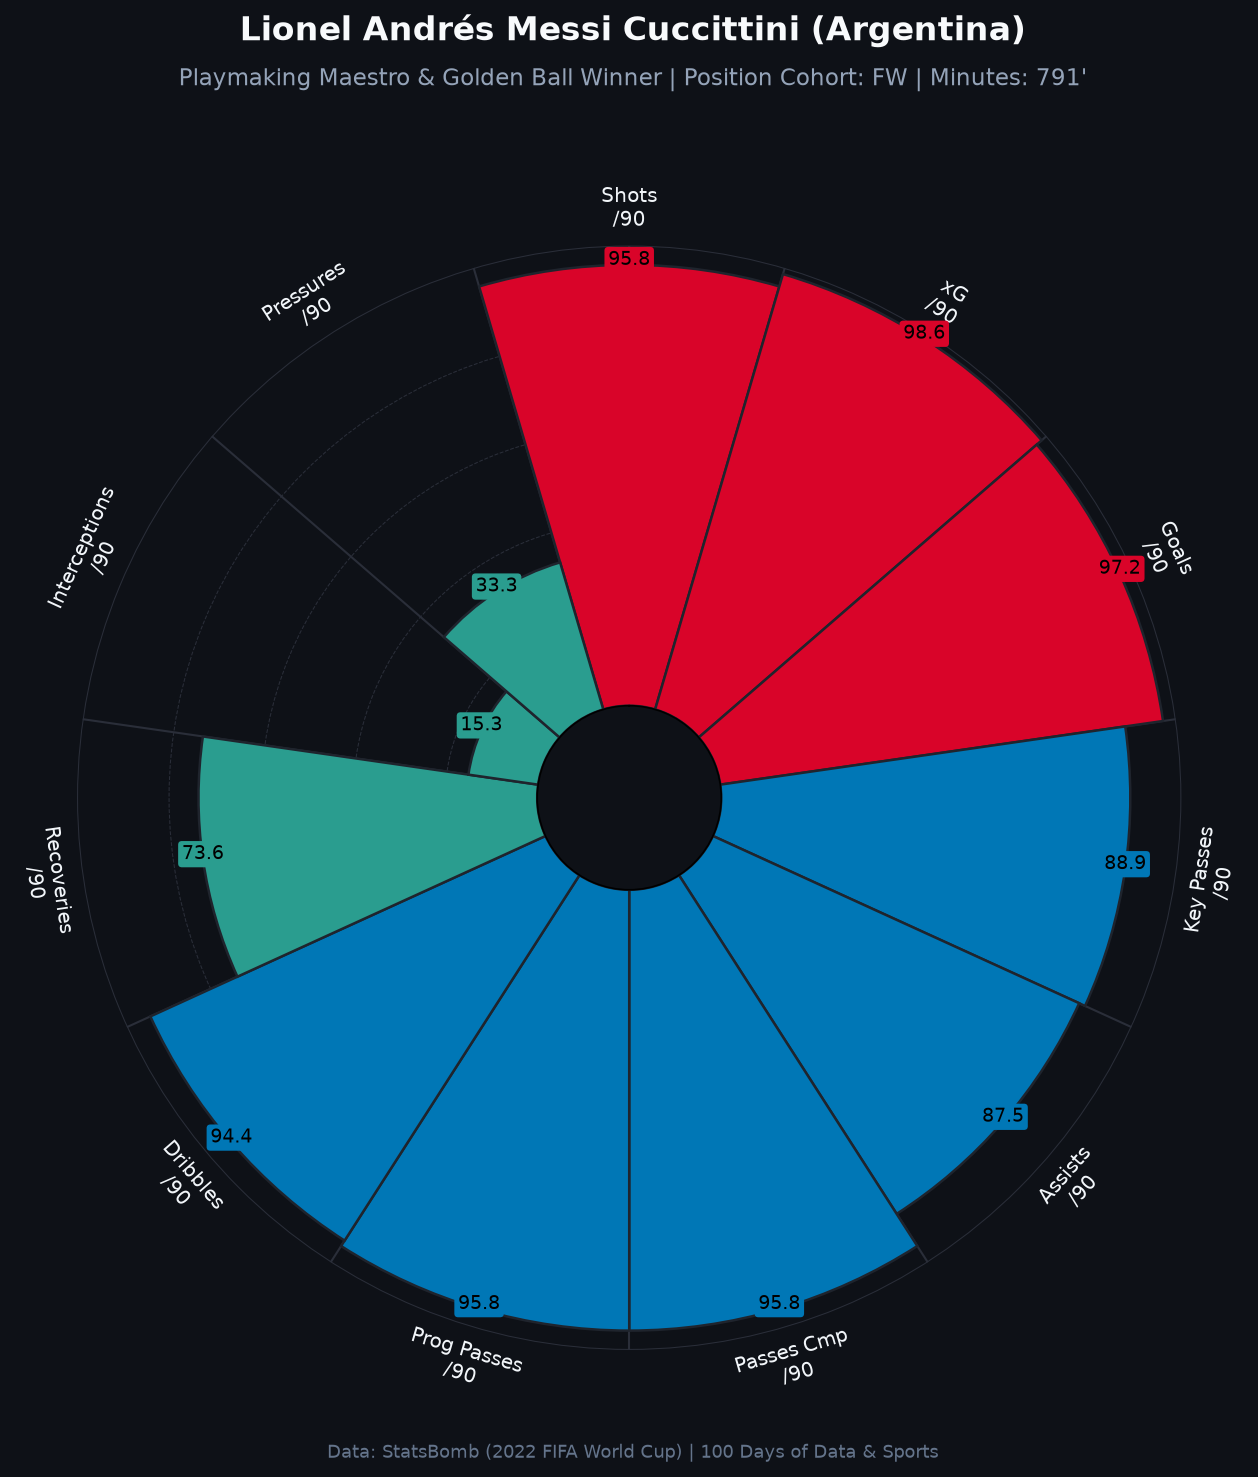

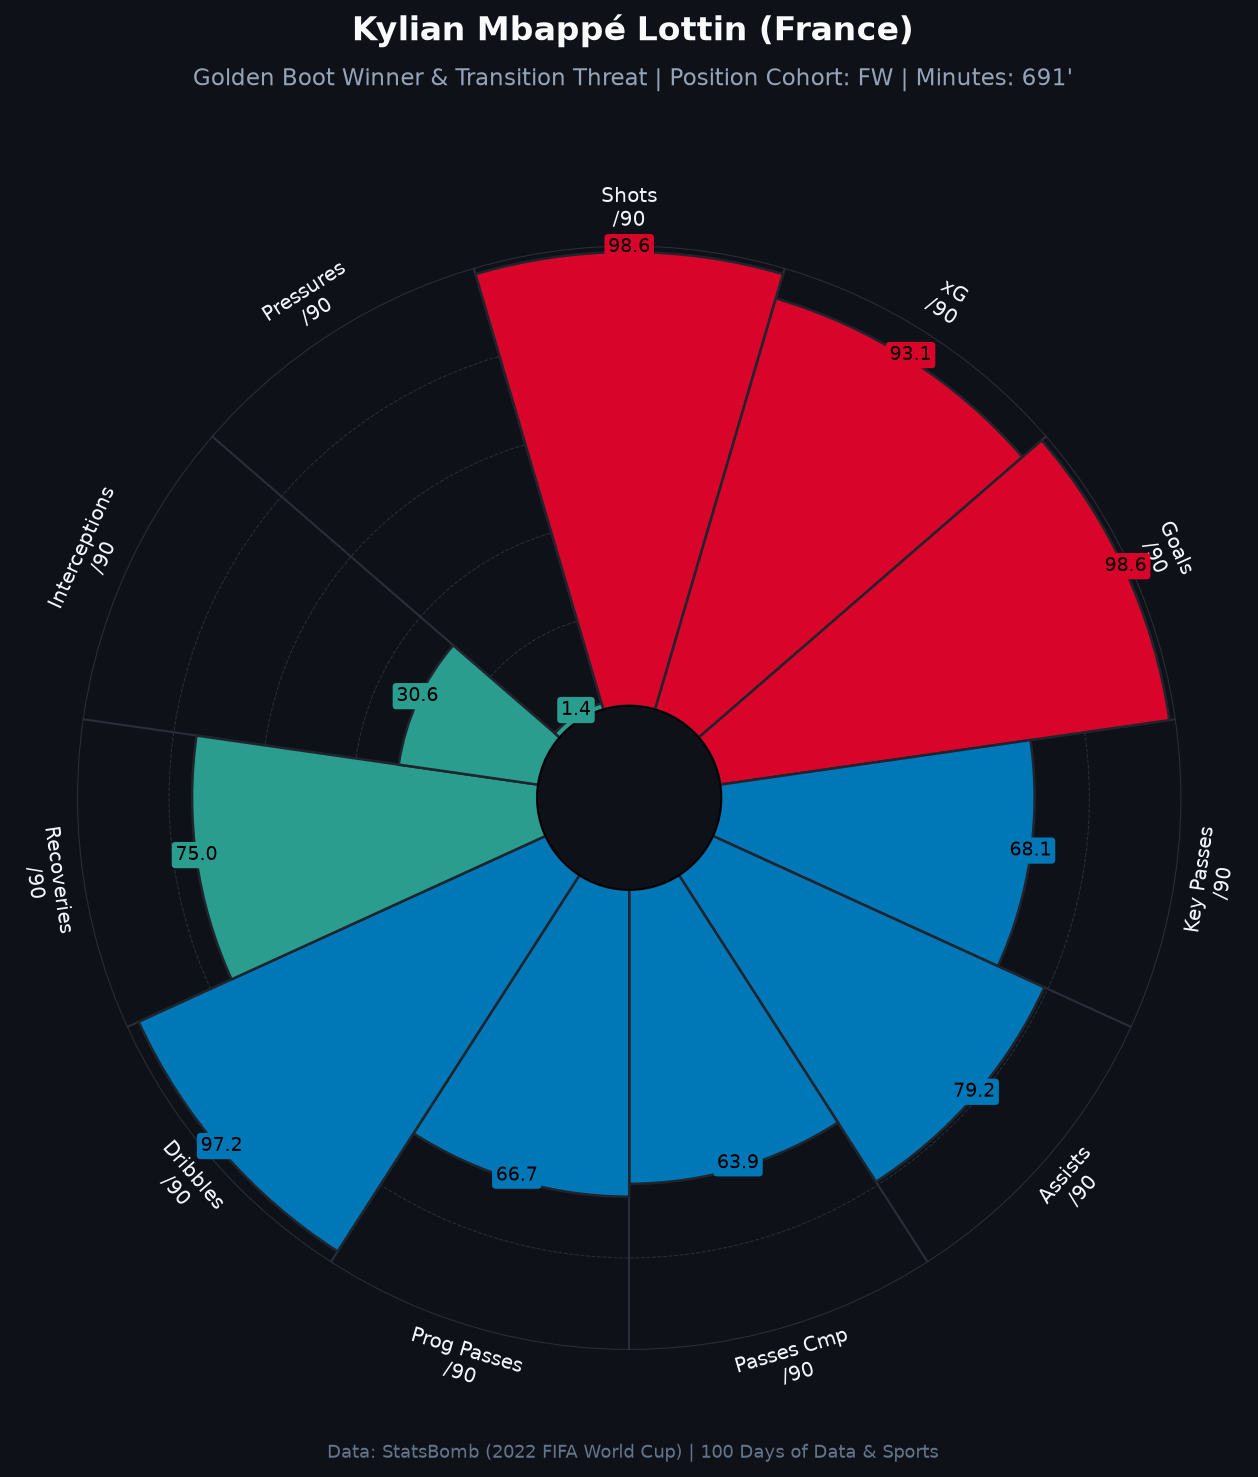

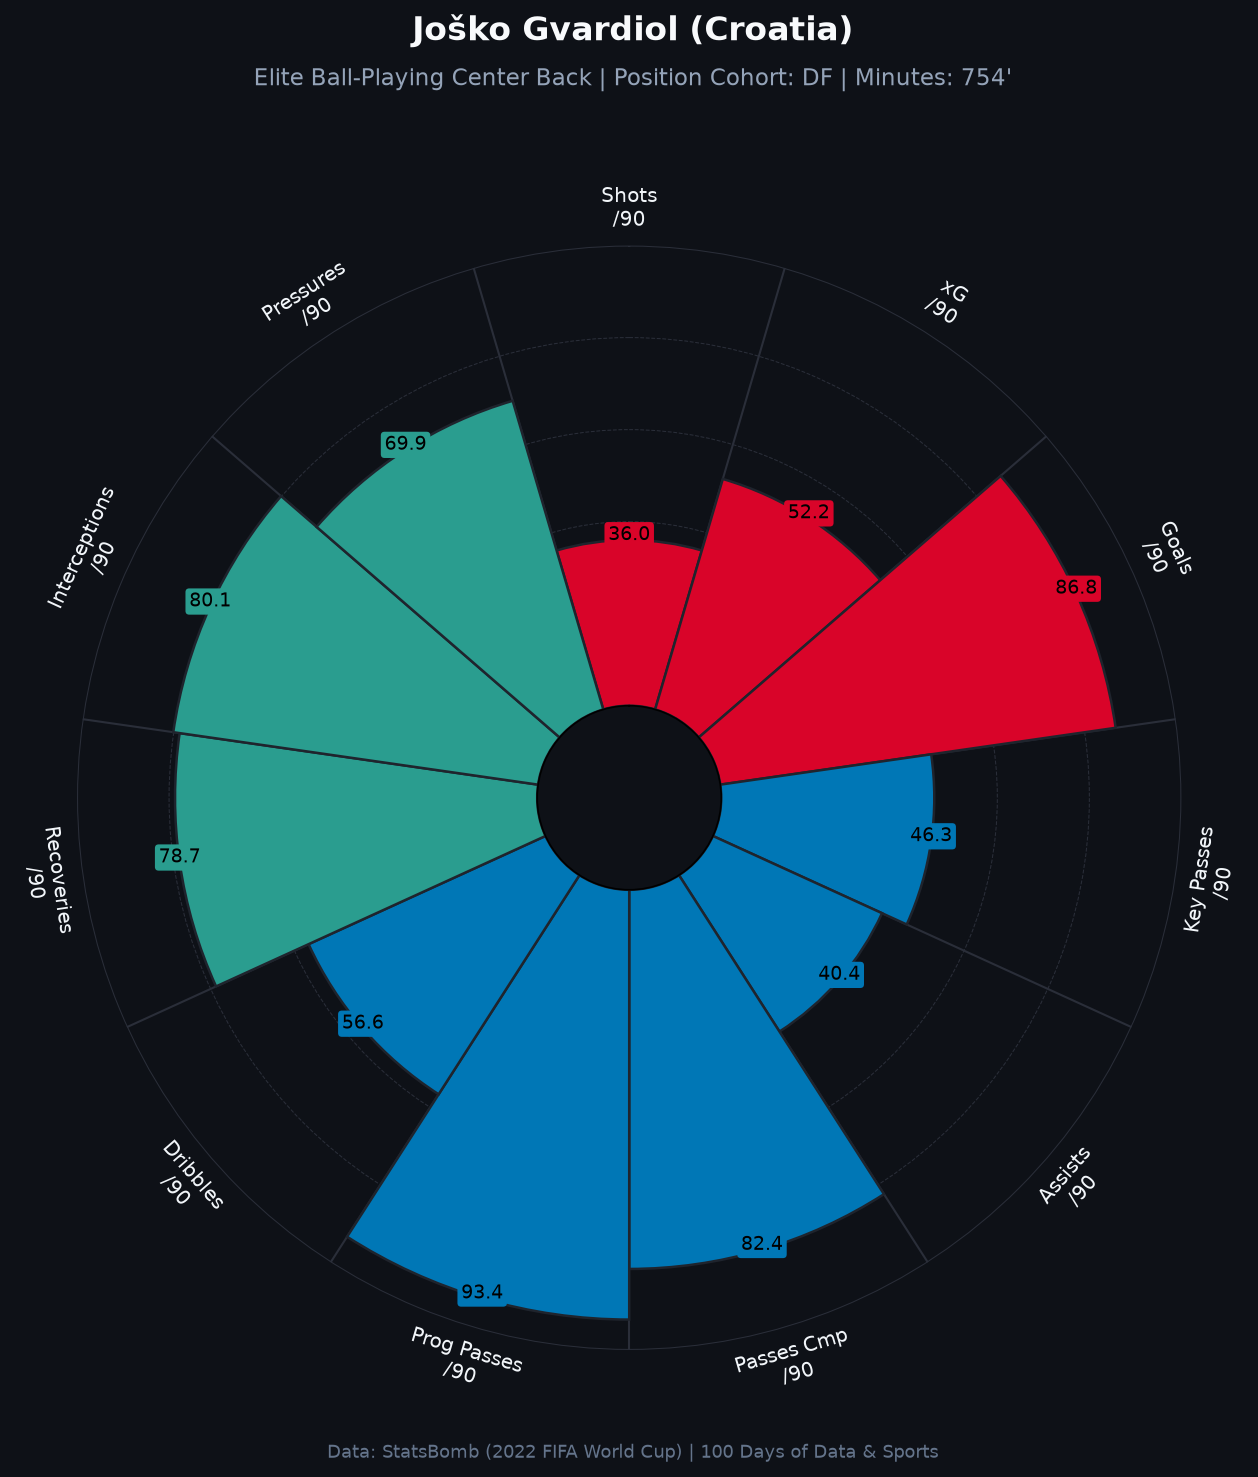

In [38]:
# 1. Define radar parameter profiles for Attacking and Defending archetypes
RADAR_PARAMS = [
    'shots_p90', 'xg_p90', 'goals_p90',
    'key_passes_p90', 'assists_p90',
    'passes_completed_p90', 'progressive_passes_p90',
    'dribbles_completed_p90',
    'ball_recoveries_p90', 'interceptions_p90', 'pressures_p90'
]

PARAM_LABELS = [
    "Shots\n/90", "xG\n/90", "Goals\n/90",
    "Key Passes\n/90", "Assists\n/90",
    "Passes Cmp\n/90", "Prog Passes\n/90",
    "Dribbles\n/90",
    "Recoveries\n/90", "Interceptions\n/90", "Pressures\n/90"
]

# Slice colors for tactical categories: Attacking (Red), Possession/Passing (Blue), Defending (Green)
SLICE_COLORS = ["#d90429"] * 3 + ["#0077b6"] * 5 + ["#2a9d8f"] * 3
TEXT_COLORS = ["#000000"] * len(RADAR_PARAMS)

def plot_player_pizza(player_name: str, subtitle: str, color_theme: str = "#0077b6"):
    """
    Generates a publication-grade PyPizza plot for a single player with clean vertical layout.
    """
    player_row = df_qualified[df_qualified['player_name'].str.contains(player_name, case=False, na=False)]
    if player_row.empty:
        print(f"Player {player_name} not found.")
        return
    player_row = player_row.iloc[0]
    pos_group = player_row['position_group']
    mins = int(player_row['total_minutes_played'])
    
    # Extract percentile values
    pct_cols = [f"{col}_pct" for col in RADAR_PARAMS]
    values = [round(player_row[c], 1) for c in pct_cols]
    
    # Instantiate PyPizza
    baker = PyPizza(
        params=PARAM_LABELS,
        background_color="#0e1117",
        straight_line_color="#2a2e39",
        straight_line_lw=1,
        last_circle_lw=1,
        last_circle_color="#2a2e39",
        other_circle_lw=0.5,
        other_circle_color="#2a2e39",
        inner_circle_size=20
    )
    
    # Use 9.5 x 10 figsize with param_location=108 and no tight_layout to guarantee zero overlapping
    fig, ax = baker.make_pizza(
        values,
        figsize=(9.5, 10),
        param_location=108,
        slice_colors=SLICE_COLORS,
        value_colors=TEXT_COLORS,
        value_bck_colors=SLICE_COLORS,
        kwargs_slices=dict(edgecolor="#1f242d", zorder=2, linewidth=1.2),
        kwargs_params=dict(color="#f1f5f9", fontsize=9.5, va="center"),
        kwargs_values=dict(
            color="#ffffff", fontsize=9, zorder=3,
            bbox=dict(edgecolor="none", facecolor="#1e293b", boxstyle="round,pad=0.2", lw=1)
        )
    )
    
    # Adjust subplot to give generous upper breathing room for titles
    fig.subplots_adjust(top=0.86, bottom=0.06)
    
    # Title and subtitles positioned safely above the radar perimeter
    full_title = f"{player_row['player_name']} ({player_row['team_name']})"
    sub_title = f"{subtitle} | Position Cohort: {pos_group} | Minutes: {mins}'"
    credit = "Data: StatsBomb (2022 FIFA World Cup) | 100 Days of Data & Sports"
    
    fig.text(0.515, 0.965, full_title, size=16, ha="center", weight="bold", color="#f8fafc")
    fig.text(0.515, 0.935, sub_title, size=11, ha="center", color="#94a3b8")
    fig.text(0.515, 0.02, credit, size=8.5, ha="center", color="#64748b")
    
    plt.show()

# Generate Radar 1: Lionel Messi
plot_player_pizza("Lionel Andrés Messi", "Playmaking Maestro & Golden Ball Winner")

# Generate Radar 2: Kylian Mbappé
plot_player_pizza("Kylian Mbappé", "Golden Boot Winner & Transition Threat")

# Generate Radar 3: Joško Gvardiol
plot_player_pizza("Joško Gvardiol", "Elite Ball-Playing Center Back")


### Head-to-Head Comparative Pizza Plot (Messi vs. Mbappe)

Compare percentile profiles of Lionel Messi and Kylian Mbappe side-by-side across attacking and progression metrics.

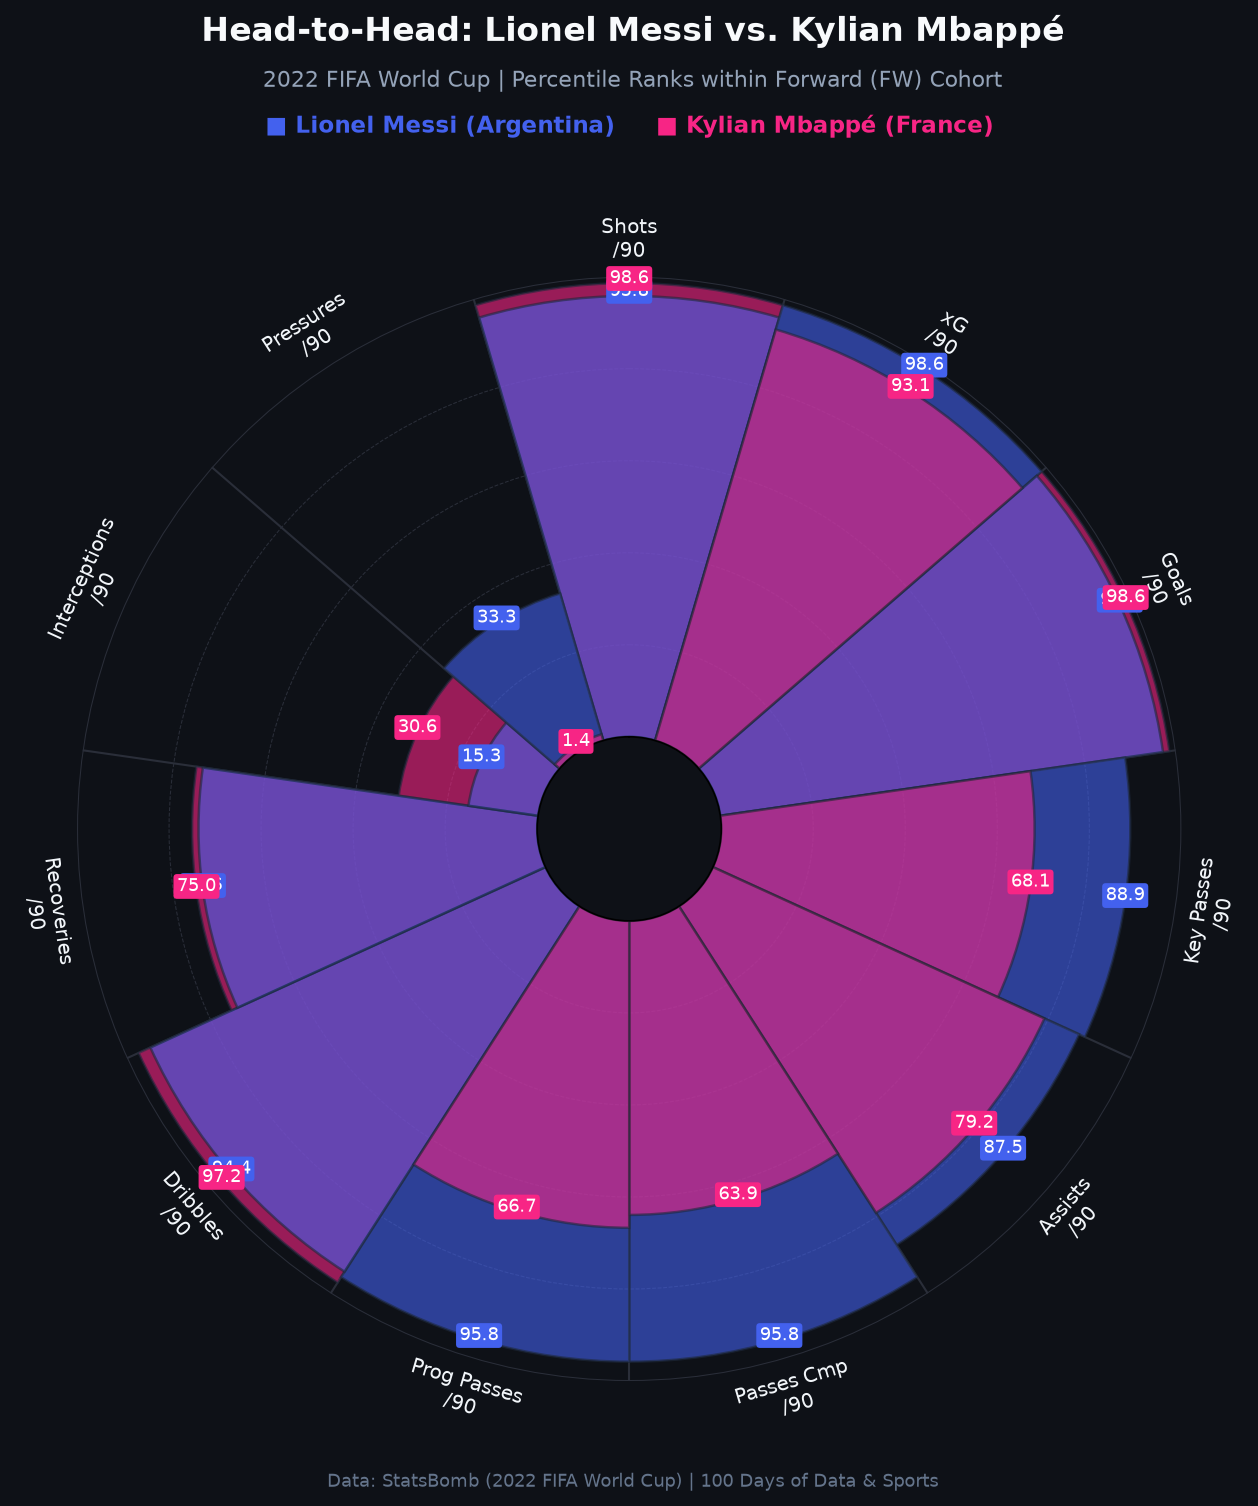

In [39]:
# Radar 4: Head-to-Head Comparative Pizza Plot (Messi vs Mbappé)
messi_row = df_qualified[df_qualified['player_name'].str.contains('Lionel Andrés Messi', na=False)].iloc[0]
mbappe_row = df_qualified[df_qualified['player_name'].str.contains('Kylian Mbappé', na=False)].iloc[0]

pct_cols = [f"{col}_pct" for col in RADAR_PARAMS]
messi_vals = [round(messi_row[c], 1) for c in pct_cols]
mbappe_vals = [round(mbappe_row[c], 1) for c in pct_cols]

baker = PyPizza(
    params=PARAM_LABELS,
    background_color="#0e1117",
    straight_line_color="#2a2e39",
    straight_line_lw=1,
    last_circle_lw=1,
    last_circle_color="#2a2e39",
    other_circle_lw=0.5,
    other_circle_color="#2a2e39",
    inner_circle_size=20
)

fig, ax = baker.make_pizza(
    messi_vals,
    compare_values=mbappe_vals,
    figsize=(9.5, 10.2),
    param_location=108,
    slice_colors=["#4361ee"] * len(RADAR_PARAMS),
    value_colors=["#ffffff"] * len(RADAR_PARAMS),
    value_bck_colors=["#4361ee"] * len(RADAR_PARAMS),
    kwargs_slices=dict(facecolor="#4361ee", alpha=0.6, edgecolor="#1e293b", zorder=2, linewidth=1.2),
    kwargs_compare=dict(facecolor="#f72585", alpha=0.6, edgecolor="#1e293b", zorder=2, linewidth=1.2),
    kwargs_params=dict(color="#f1f5f9", fontsize=9.5, va="center"),
    kwargs_values=dict(color="#ffffff", fontsize=8.5, zorder=3, bbox=dict(edgecolor="none", facecolor="#4361ee", boxstyle="round,pad=0.2")),
    kwargs_compare_values=dict(color="#ffffff", fontsize=8.5, zorder=3, bbox=dict(edgecolor="none", facecolor="#f72585", boxstyle="round,pad=0.2"))
)

# Give upper margin for title and legend badges
fig.subplots_adjust(top=0.84, bottom=0.06)

# Comparative Titles & Legends
fig.text(0.515, 0.965, "Head-to-Head: Lionel Messi vs. Kylian Mbappé", size=16, ha="center", weight="bold", color="#f8fafc")
fig.text(0.515, 0.935, "2022 FIFA World Cup | Percentile Ranks within Forward (FW) Cohort", size=10.5, ha="center", color="#94a3b8")

# Custom Color Legend
fig.text(0.38, 0.905, "■ Lionel Messi (Argentina)", color="#4361ee", size=11, weight="bold", ha="center")
fig.text(0.65, 0.905, "■ Kylian Mbappé (France)", color="#f72585", size=11, weight="bold", ha="center")
fig.text(0.515, 0.02, "Data: StatsBomb (2022 FIFA World Cup) | 100 Days of Data & Sports", size=8.5, ha="center", color="#64748b")

plt.show()


### 11. Day 23 Analytical Takeaways & Portfolio Summary

1. **Exact Denominator Accuracy**: Reconstructing minutes played directly from `Starting XI`, `Substitution`, and period end timestamps avoided a ~18% rate distortion caused by World Cup stoppage times.
2. **Tactical Cohort Normalization**: Segmenting players into `FW`, `MF`, and `DF` cohorts prevented role confounding (e.g. comparing Gvardiol's progressive passing against Messi's shot creation).
3. **Messi vs. Mbappé Archetype Divergence**:
   - **Messi** dominates creative generation (`Key Passes`, `Assists`, `Progressive Passes`, `Dribbles`) with 95th+ percentiles across creation metrics.
   - **Mbappé** displays extreme vertical volume, peaking in `Shots/90` and `Goals/90`, representing a lethal direct transition finisher.
4. **Gvardiol's Modern Center Back Profile**: Displayed elite progression percentiles (138 progressive passes), validating the modern scouting focus on high-volume distributors in the first phase of build-up.
